# Predicción del rendimiento y del riesgo de reprobación en lengua portuguesa en estudiantes de secundaria: un enfoque de ciencia de datos con dashboard interactivo

Andrés Felipe Ricaurte Cortés

Maestría en Inteligencia Artificial
Universidad de La Salle, Bogotá, Colombia
Asignatura: Ciencia de Datos, Grupo 2. Proyecto Integrador, Fase 4 (Actividades 7, 8 y 9)

Noviembre de 2026

## Resumen

Se trabajó con el archivo de lengua portuguesa del conjunto Student Performance (649 estudiantes de dos escuelas de secundaria de Portugal) para responder en qué medida las características académicas, familiares y de hábitos permiten predecir la nota final y la aprobación, y qué perfiles de estudiantes se pueden distinguir. Los datos se limpiaron y se partieron de forma estratificada en entrenamiento, validación y prueba sin fuga de datos. Se compararon modelos lineales regularizados, de ensambles, máquinas de soporte vectorial y un perceptrón multicapa en tres escenarios según la información disponible: sin notas, con la nota del primer periodo y con las notas de los dos primeros periodos. En el conjunto de prueba, la regresión alcanzó un R² de 0,31 sin notas (el error baja 11 % frente al modelo base), de 0,76 con G1 y de 0,90 con G1 y G2. En clasificación los modelos ajustados no superaron de forma consistente a los modelos base: el AUC fue de 0,66, 0,88 y 0,95, con intervalos de confianza muy amplios porque la prueba tiene solo 15 reprobados. La segmentación con K-Means produjo cuatro perfiles con tasas de reprobación de 5 % a 54 %, aunque la silueta fue baja (0,10) porque los estudiantes forman un continuo. Los resultados se entregan en un dashboard interactivo con filtros, indicadores, predicción en vivo y mapa de grupos, empaquetado con dependencias fijas y pruebas automáticas. El hallazgo principal es que, antes de conocer cualquier nota, el contexto y los hábitos explican cerca de un tercio de la variación de la nota final, y que una vez se conocen las notas parciales casi todo el poder predictivo proviene de ellas.

Palabras clave: rendimiento académico, minería de datos educativa, regresión, clasificación, agrupamiento, dashboard.

## Contenido

1. Introducción
2. Metodología
3. Resultados
4. Discusión
5. Conclusiones
6. Trabajo futuro
7. Referencias
8. Anexo A. Reproducibilidad, despliegue y lista de chequeo

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import (mean_squared_error, r2_score, mean_absolute_error, roc_auc_score, roc_curve, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score, silhouette_score)

# El cuaderno vive en la carpeta notebooks del repositorio; se agrega src al camino de búsqueda
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from rendimiento import core

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "legend.frameon": False,
})
AZUL, NARANJA, VERDE, AMARILLO, CELESTE, GRIS = "#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#B0B0B0"
ESC, nominales = core.ESCENARIOS, core.config()["nominales"]
df, res = core.datos(), core.resultados()

# Verificación de concordancia con las fases 1, 2 y 3
assert df.shape[0] == 649 and int(df["aprobado"].sum()) == 549 and int((df["G3"] == 0).sum()) == 15
assert df["particion"].value_counts().to_dict() == {"entrenamiento": 454, "validación": 97, "prueba": 98}
assert res["k_elegido"] == 4 and res["usar_smote"] is False
print("Datos y particiones coinciden con las fases anteriores:", df.shape[0], "estudiantes;", df["particion"].value_counts().to_dict())
print("Modelos finales:", res["elegidos"])
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| numpy", np.__version__)

Datos y particiones coinciden con las fases anteriores: 649 estudiantes; {'entrenamiento': 454, 'prueba': 98, 'validación': 97}
Modelos finales: {'reg|Sin notas': 'XGBoost', 'reg|Con G1': 'ElasticNet', 'reg|Con G1 y G2': 'Lasso', 'clf|Sin notas': 'XGBoost', 'clf|Con G1': 'Logística', 'clf|Con G1 y G2': 'XGBoost'}
pandas 3.0.5 | matplotlib 3.11.2 | numpy 2.5.3


La primera celda carga el paquete del repositorio (carpeta src), los datos preparados en la Fase 2 y los modelos entrenados en la Fase 3, y comprueba que las cifras coinciden con las de los cuadernos anteriores. Todo lo que se reporta a continuación se recalcula desde esos archivos, de modo que el informe se puede reproducir ejecutando el cuaderno.

## 1. Introducción

El fracaso escolar es uno de los problemas más persistentes de la educación secundaria, y detectarlo tarde deja poco margen para intervenir. Desde la minería de datos educativa se ha propuesto estimar el rendimiento de los estudiantes a partir de la información que la escuela ya recoge (Romero y Ventura, 2010). Cortez y Silva (2008) publicaron un conjunto de datos con notas, hábitos y contexto familiar de estudiantes de dos escuelas portuguesas, y mostraron que las notas parciales son los mejores predictores de la nota final. Eso es útil para predecir, pero reduce el valor práctico si lo que se quiere es actuar con anticipación, porque cuando las notas parciales ya existen una parte del año ha pasado.

Este trabajo retoma ese problema con un enfoque de proyecto completo, desde la exploración hasta un producto utilizable. Las fases anteriores del Proyecto Integrador resolvieron la formulación del problema y el análisis exploratorio (Fase 1), la limpieza, la ingeniería de variables, la partición y los modelos base (Fase 2), y el modelado avanzado, la interpretabilidad y la segmentación (Fase 3). Esta fase final integra todo en un informe de estructura científica y en un dashboard interactivo.

La pregunta de investigación principal sigue siendo la de la Fase 1: en qué medida las características académicas, familiares y de hábitos de los estudiantes permiten predecir su nota final y su aprobación en lengua portuguesa, y qué perfiles de estudiantes se pueden distinguir. Las preguntas secundarias fueron qué variables se asocian más con el desempeño, cuánto aportan las notas parciales frente al contexto y si existen grupos con perfiles diferenciados. El objetivo general es entregar una solución analítica reproducible, publicada como dashboard, con un informe técnico y un repositorio abierto. El aporte del trabajo es doble: una evaluación honesta de qué tanto se puede predecir en cada momento del año, y un paquete que permite explorar y usar esos modelos con facilidad.

## 2. Metodología

### 2.1 Datos

Se usó el archivo student-por.csv del repositorio UCI Machine Learning Repository (Cortez y Silva, 2008; https://doi.org/10.24432/C5TG7T), con licencia CC BY 4.0. Contiene 649 estudiantes y 33 variables: datos demográficos, contexto familiar, hábitos de estudio y ocio, ausencias y tres notas en escala de 0 a 20 (G1 y G2 de los dos primeros periodos y G3 final). No tiene datos faltantes ni duplicados. La variable objetivo de regresión es G3. Para la clasificación se creó la variable aprobado, que vale 1 cuando G3 es 10 o más, de modo que la clase de interés es reprobar (15,4 % de los estudiantes).

### 2.2 Preparación de los datos

Las decisiones de limpieza surgieron del análisis exploratorio y se documentaron en la Fase 2. Quince estudiantes tienen nota final igual a cero, catorce de ellos de la escuela MS y todos con cero ausencias; el análisis del mecanismo de falta descartó que fueran faltantes completamente al azar y el patrón es compatible con abandonos, por lo que no se imputaron: se excluyeron de la regresión y se conservaron en la clasificación como reprobados. Un único G1 igual a cero, incoherente con las demás notas del estudiante, se trató como error de captura y se imputó con la mediana del entrenamiento. Las ausencias, con una cola larga, se transformaron con log(1 + x). Se crearon seis variables derivadas: consumo total de alcohol, educación promedio de los padres, indicador de reprobaciones previas, ausencias en logaritmo, tendencia entre G1 y G2 y número de apoyos recibidos.

Los datos se partieron de forma estratificada por aprobación en 70 % para entrenamiento (454 estudiantes), 15 % para validación (97) y 15 % para prueba (98), con semilla fija. Todo transformador que aprende parámetros (imputadores, codificación one-hot y estandarización) se ajusta únicamente con el entrenamiento dentro de un Pipeline de scikit-learn (Pedregosa et al., 2011), lo que evita la fuga de datos; en la Fase 2 se verificó que el escalador guardó las medias del entrenamiento y no las de todos los datos.

### 2.3 Modelado supervisado

Como las notas parciales dominan la predicción, todo se repitió en tres escenarios según la información disponible, que se resumen en la Tabla 1. El escenario con G1 no estaba en la Fase 2 y se agregó en la Fase 3 porque es el punto intermedio que tiene sentido en la práctica.

| Escenario | Información usada | Momento en que estaría disponible |
|---|---|---|
| Sin notas | Contexto, hábitos y variables derivadas | Inicio del año |
| Con G1 | Lo anterior más la nota del primer periodo | Después del primer periodo |
| Con G1 y G2 | Lo anterior más la nota del segundo periodo y la tendencia | Después del segundo periodo |

Tabla 2. Escenarios de variables predictoras. Fuente: elaboración propia.

En regresión se compararon Ridge, Lasso y ElasticNet (Hoerl y Kennard, 1970; Tibshirani, 1996; Zou y Hastie, 2005), Random Forest (Breiman, 2001) y XGBoost (Chen y Guestrin, 2016). En clasificación se compararon la regresión logística, una máquina de soporte vectorial con núcleo gaussiano, Random Forest y XGBoost, además de un perceptrón multicapa en PyTorch para ambas tareas (Paszke et al., 2019). Los hiperparámetros se eligieron con validación cruzada de cinco pliegues sobre el entrenamiento (repetida dos veces en clasificación) y el desbalance de clases se manejó con pesos de clase, porque SMOTE (Chawla et al., 2002) no mejoró la precisión promedio en más de 0,01, regla definida de antemano. El mejor modelo de cada tarea y escenario se eligió en validación (por RMSE en regresión y por precisión promedio en clasificación), se reajustó con entrenamiento y validación juntos (551 estudiantes) y se evaluó una única vez en la prueba. En clasificación el umbral de decisión se ajustó con probabilidades fuera de muestra del entrenamiento y la validación, y la incertidumbre de las métricas se estimó con intervalos de confianza bootstrap de 1.000 remuestreos (Efron y Tibshirani, 1993).

### 2.4 Segmentación e interpretabilidad

Para la segmentación se usaron 13 variables de hábitos y contexto, sin las notas, estandarizadas con los parámetros del entrenamiento. El número de grupos se decidió con el método del codo y el coeficiente de silueta (Rousseeuw, 1987), con la regla de tomar el K de mayor silueta entre 3 y 8. Se compararon K-Means (Lloyd, 1982), el clustering jerárquico con enlace de Ward y DBSCAN (Ester et al., 1996). Para entender qué variables pesan en los modelos se usaron valores SHAP (Lundberg y Lee, 2017) y la importancia por permutación, ambos en la Fase 3.

### 2.5 Dashboard y paquete de software

El dashboard se construyó con Streamlit y Plotly (Plotly Technologies Inc., 2015; Streamlit Inc., s. f.) y se organiza en cinco pestañas: panorama con filtros dinámicos e indicadores clave, predicción en vivo, segmentación con el mapa de grupos, comparación de modelos y datos. Se priorizó que fuera eficiente de ejecutar: los modelos ya entrenados se cargan una sola vez en memoria y se reutilizan en cada interacción, la predicción de un estudiante nuevo es una sola llamada a modelos pequeños, y el paquete fija las versiones exactas de las dependencias en requirements.txt para que los archivos de los modelos se carguen sin problemas. El anexo A describe la estructura del repositorio y cómo ejecutarlo.

## 3. Resultados

### 3.1 Datos y partición

Antes de los modelos se resume cómo quedó la partición y cómo se distribuye la nota final. La partición conserva la proporción de reprobados y los ceros de la nota final quedaron repartidos entre los tres conjuntos.

In [2]:
filas = []
for p in ["entrenamiento", "validación", "prueba"]:
    s = df[df["particion"] == p]
    filas.append({"Partición": p, "Estudiantes": len(s), "Reprobados": int((s["aprobado"] == 0).sum()), "% reprobados": round((s["aprobado"] == 0).mean() * 100, 1),
                  "Ceros en G3": int((s["G3"] == 0).sum()), "Filas para regresión": int((s["G3"] > 0).sum())})
tabla_part = pd.DataFrame(filas).set_index("Partición")
tabla_part

,Estudiantes,Reprobados,% reprobados,Ceros en G3,Filas para regresión
Partición,,,,,
entrenamiento,454,70,15.4,8,446
validación,97,15,15.5,5,92
prueba,98,15,15.3,2,96


Tabla 3. Composición de las particiones de entrenamiento, validación y prueba. Fuente: elaboración propia con datos de Cortez y Silva (2008).

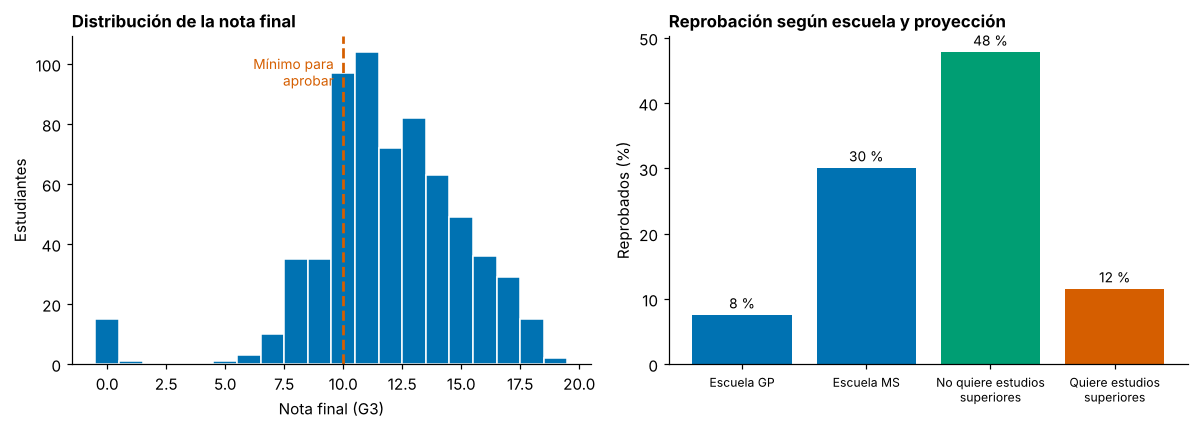

Tasas de reprobación: {'Escuela GP': 7.6, 'Escuela MS': 30.1, 'No quiere estudios\nsuperiores': 47.8, 'Quiere estudios\nsuperiores': 11.6}


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(df["G3"], bins=np.arange(-0.5, 20.5, 1), color=AZUL, edgecolor="white")
ax1.axvline(10, color=NARANJA, ls="--", lw=1.8); ax1.text(9.6, ax1.get_ylim()[1] * 0.85, "Mínimo para\naprobar", color=NARANJA, ha="right", fontsize=9)
ax1.set_xlabel("Nota final (G3)"); ax1.set_ylabel("Estudiantes"); ax1.set_title("Distribución de la nota final")
raw = pd.read_csv(core.RAIZ / "data" / "student-por.csv")
g = raw.assign(rep=(raw["G3"] < 10).astype(int))
t = pd.concat([g.groupby("school")["rep"].mean().rename(lambda x: f"Escuela {x}"), g.groupby("higher")["rep"].mean().rename({"yes": "Quiere estudios\nsuperiores", "no": "No quiere estudios\nsuperiores"})]) * 100
ax2.bar(t.index, t.values, color=[AZUL, AZUL, VERDE, NARANJA])
for i, v in enumerate(t.values): ax2.text(i, v + 1, f"{v:.0f} %", ha="center", fontsize=9)
ax2.set_ylabel("Reprobados (%)"); ax2.set_title("Reprobación según escuela y proyección"); ax2.tick_params(axis="x", labelsize=8)
fig.tight_layout(); plt.show()
print("Tasas de reprobación:", t.round(1).to_dict())

Figura 1. Distribución de la nota final y tasa de reprobación según la escuela y el deseo de cursar educación superior. Fuente: elaboración propia con datos de Cortez y Silva (2008).

La nota final se concentra entre 10 y 16 y tiene un grupo separado de quince estudiantes en cero, que son los casos tratados aparte. La reprobación es mucho mayor en la escuela MS y entre quienes no quieren cursar educación superior, dos de las asociaciones más fuertes que ya había mostrado el análisis exploratorio.

### 3.2 Regresión de la nota final

Los modelos finales de regresión se evaluaron una sola vez en el conjunto de prueba (96 estudiantes con nota real). Se recalculan sus métricas desde los modelos guardados y se agregan intervalos de confianza bootstrap. Los modelos base (regresión lineal simple con una sola variable) se reajustaron en la Fase 3 con el mismo protocolo; sus resultados se toman de ese cuaderno.

In [4]:
def bootstrap(y, pred, fn, n=1000):
    rng = np.random.default_rng(42); y = np.asarray(y); pred = np.asarray(pred); v = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        try: v.append(fn(y[i], pred[i]))
        except ValueError: continue
    return np.percentile(v, [2.5, 97.5])

rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
te = df[df["particion"] == "prueba"]
REG, CLF = {}, {}
for esc in ESC:
    cols = core.columnas(esc) + nominales
    d = te[te["G3"] > 0]; pred = core.modelo("reg", esc).predict(d[cols])
    REG[esc] = {"y": d["G3"].values, "pred": pred, "RMSE": rmse(d["G3"], pred), "R2": r2_score(d["G3"], pred), "MAE": mean_absolute_error(d["G3"], pred),
                "ic_rmse": bootstrap(d["G3"], pred, rmse), "n": len(d)}
    y = (1 - te["aprobado"]).values; p = core.modelo("clf", esc).predict_proba(te[cols])[:, 1]; u = res["umbrales"][esc]; h = (p >= u).astype(int)
    CLF[esc] = {"y": y, "p": p, "umbral": u, "pred": h, "Exactitud": accuracy_score(y, h), "Precisión": precision_score(y, h, zero_division=0), "Recall": recall_score(y, h),
                "F1": f1_score(y, h), "AUC": roc_auc_score(y, p),
                "ic_f1": bootstrap(y, p, lambda a, b: f1_score(a, (b >= u).astype(int), zero_division=0)), "ic_auc": bootstrap(y, p, roc_auc_score)}
    # las métricas recalculadas deben coincidir con las guardadas en la Fase 3
    assert abs(REG[esc]["RMSE"] - res["test_reg"][esc]["RMSE"]) < 1e-9 and abs(CLF[esc]["AUC"] - res["test_clf"][esc]["AUC"]) < 1e-9

filas = []
for esc in ESC:
    r, b = REG[esc], core.BASE_PRUEBA[esc]
    filas.append({"Escenario": esc, "Modelo final": res["elegidos"][f"reg|{esc}"], "n": r["n"], "RMSE": r["RMSE"], "IC 95 % RMSE": f"[{r['ic_rmse'][0]:.2f}, {r['ic_rmse'][1]:.2f}]",
                  "R2": r["R2"], "MAE": r["MAE"], "RMSE base": b["RMSE"], "R2 base": b["R2"], "Reducción del RMSE (%)": (1 - r["RMSE"] / b["RMSE"]) * 100})
tabla_reg = pd.DataFrame(filas).set_index("Escenario")
tabla_reg.round(3)

,Modelo final,n,RMSE,IC 95 % RMSE,R2,MAE,RMSE base,R2 base,Reducción del RMSE (%)
Escenario,,,,,,,,,
Sin notas,XGBoost,96,2.178,"[1.87, 2.43]",0.307,1.785,2.452,0.122,11.180
Con G1,ElasticNet,96,1.294,"[1.11, 1.48]",0.756,0.977,1.305,0.751,0.866
Con G1 y G2,Lasso,96,0.812,"[0.69, 0.94]",0.904,0.638,0.833,0.899,2.569


Tabla 4. Regresión de la nota final en el conjunto de prueba: modelo final y modelo base. El modelo base usa una sola variable (reprobaciones previas sin notas, G1 con G1, G2 con G1 y G2). Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. Sin notas, el modelo final (XGBoost) logra un RMSE de 2,18 puntos con un R² de 0,31, frente a 2,45 y 0,12 del modelo base, es decir una reducción del error de 11 % y un R² que se multiplica por 2,5. El intervalo de confianza del modelo final (1,87 a 2,43) queda por debajo del error del base, aunque como el base no tiene intervalo no se puede afirmar que la diferencia sea estadísticamente significativa. El error medio absoluto es de 1,8 puntos sobre 20. Con G1 el modelo final (ElasticNet) y el base prácticamente empatan (1,29 contra 1,30, una mejora de 0,9 %), y con G1 y G2 el modelo final (Lasso) llega a un RMSE de 0,81 y un R² de 0,90 contra 0,83 y 0,90 del base, una mejora de 2,6 % que cabe dentro del margen de incertidumbre (0,69 a 0,94). En resumen, la regresión mejora de forma clara solo en el escenario sin notas, que es justamente donde el modelo base era más pobre; cuando hay notas parciales una recta con una sola variable ya hace casi todo el trabajo.

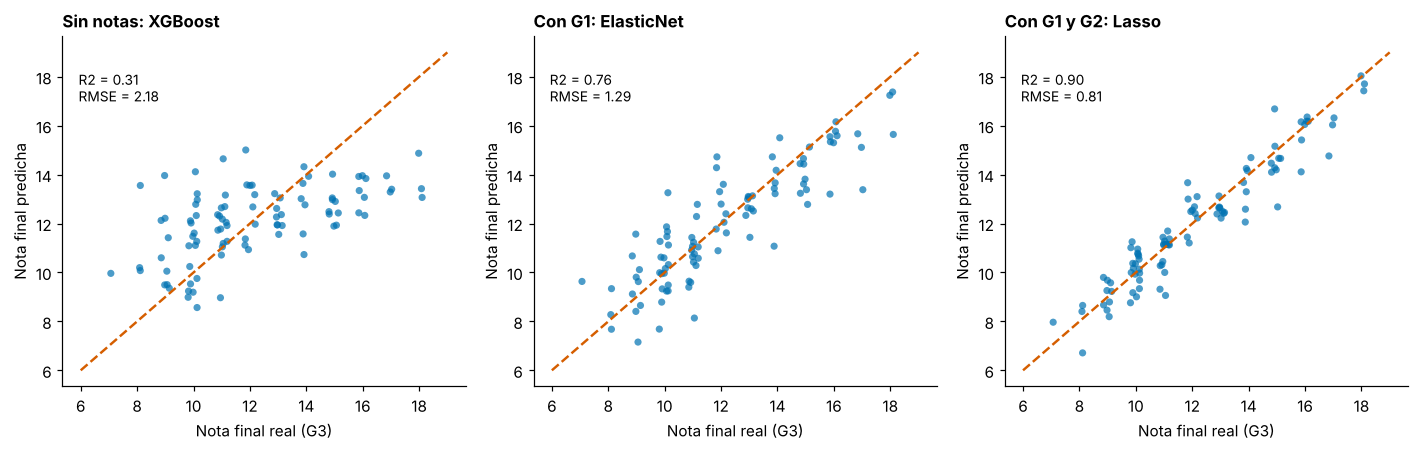

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, esc in zip(ejes, ESC):
    r = REG[esc]; rng = np.random.default_rng(42)
    ax.scatter(r["y"] + rng.uniform(-.2, .2, len(r["y"])), r["pred"], s=22, alpha=.7, color=AZUL, edgecolor="none")
    lim = [r["y"].min() - 1, r["y"].max() + 1]; ax.plot(lim, lim, color=NARANJA, ls="--", lw=1.6)
    ax.set_title(f"{esc}: {res['elegidos']['reg|' + esc]}"); ax.set_xlabel("Nota final real (G3)"); ax.set_ylabel("Nota final predicha")
    ax.text(0.04, 0.9, f"R2 = {r['R2']:.2f}\nRMSE = {r['RMSE']:.2f}", transform=ax.transAxes, fontsize=9, va="top")
fig.tight_layout(); plt.show()

Figura 2. Nota final predicha frente a la real en el conjunto de prueba, por escenario. La línea naranja es la predicción perfecta. Fuente: elaboración propia con datos de Cortez y Silva (2008).

### 3.3 Clasificación de la aprobación

Para la clasificación, la clase positiva es reprobar. Se reportan las métricas con el umbral ajustado en cada escenario y se comparan con las del modelo base, que tuvo el mismo tratamiento.

In [6]:
filas = []
for esc in ESC:
    c, b = CLF[esc], core.BASE_PRUEBA[esc]
    filas.append({"Escenario": esc, "Modelo final": res["elegidos"][f"clf|{esc}"], "Umbral": round(c["umbral"], 2), "Exactitud": c["Exactitud"], "Precisión": c["Precisión"], "Recall": c["Recall"],
                  "F1": c["F1"], "IC 95 % F1": f"[{c['ic_f1'][0]:.2f}, {c['ic_f1'][1]:.2f}]", "AUC": c["AUC"], "IC 95 % AUC": f"[{c['ic_auc'][0]:.2f}, {c['ic_auc'][1]:.2f}]",
                  "F1 base": b["F1"], "AUC base": b["AUC"]})
tabla_clf = pd.DataFrame(filas).set_index("Escenario")
print("Reprobados en la prueba:", int(CLF["Sin notas"]["y"].sum()), "de", len(te))
tabla_clf.round(3)

Reprobados en la prueba: 15 de 98


,Modelo final,Umbral,Exactitud,Precisión,Recall,F1,IC 95 % F1,AUC,IC 95 % AUC,F1 base,AUC base
Escenario,,,,,,,,,,,
Sin notas,XGBoost,0.58,0.776,0.267,0.267,0.267,"[0.07, 0.48]",0.659,"[0.48, 0.82]",0.400,0.680
Con G1,Logística,0.72,0.847,0.500,0.600,0.545,"[0.32, 0.73]",0.880,"[0.79, 0.95]",0.524,0.900
Con G1 y G2,XGBoost,0.61,0.878,0.579,0.733,0.647,"[0.43, 0.81]",0.953,"[0.90, 0.99]",0.714,0.976


Tabla 5. Clasificación de la clase reprobado en el conjunto de prueba: modelo final y modelo base. Fuente: elaboración propia con datos de Cortez y Silva (2008).

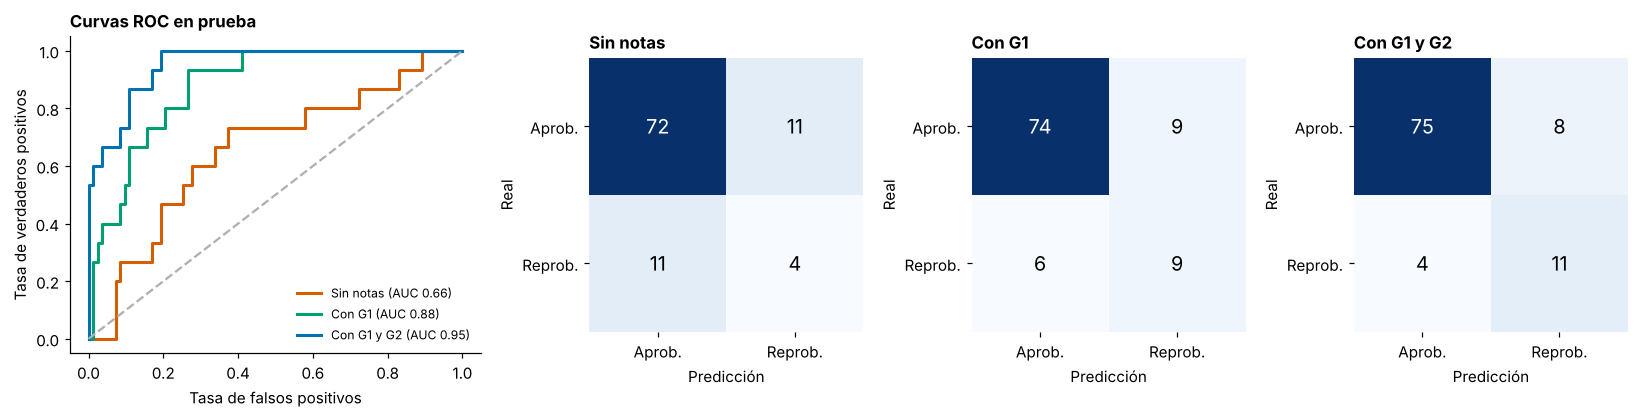

In [7]:
fig = plt.figure(figsize=(15, 3.9)); gs = fig.add_gridspec(1, 4, width_ratios=[1.5, 1, 1, 1])
ax = fig.add_subplot(gs[0]); col = {"Sin notas": NARANJA, "Con G1": VERDE, "Con G1 y G2": AZUL}
for esc in ESC:
    fpr, tpr, _ = roc_curve(CLF[esc]["y"], CLF[esc]["p"]); ax.plot(fpr, tpr, color=col[esc], lw=2, label=f"{esc} (AUC {CLF[esc]['AUC']:.2f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--"); ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos"); ax.set_title("Curvas ROC en prueba"); ax.legend(fontsize=8, loc="lower right")
for k, esc in enumerate(ESC):
    ax = fig.add_subplot(gs[k + 1]); cm = confusion_matrix(CLF[esc]["y"], CLF[esc]["pred"]); ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Aprob.", "Reprob."]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Aprob.", "Reprob."])
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title(esc)
    for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); plt.show()

Figura 3. Curvas ROC y matrices de confusión de los modelos de clasificación finales en el conjunto de prueba. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. Los tres escenarios muestran una capacidad de discriminación muy distinta. Con G1 y G2 el AUC es de 0,95 (intervalo de 0,90 a 0,99) y el modelo detecta 11 de los 15 reprobados señalando en total a 19 estudiantes, es decir con 8 falsos positivos. Con G1 el AUC es de 0,88 (0,79 a 0,95) y detecta 9 de 15 con 9 falsos positivos. Sin notas el AUC es de 0,66 y su intervalo (0,48 a 0,82) incluye el 0,5, que es el nivel del azar: con estos datos no se puede descartar que ese modelo no sea mejor que adivinar, y detecta solo 4 de los 15 reprobados con 11 falsos positivos (F1 de 0,27). Frente a los modelos base, el F1 del modelo final es mayor solo con G1 (0,55 contra 0,52) y menor sin notas (0,27 contra 0,40) y con G1 y G2 (0,65 contra 0,71), y el AUC es menor en los tres casos. Con 15 reprobados en la prueba un estudiante cambia el recall en 6,7 puntos, y los intervalos de cada modelo se traslapan por completo con los valores del base, por lo que estas diferencias no son concluyentes.

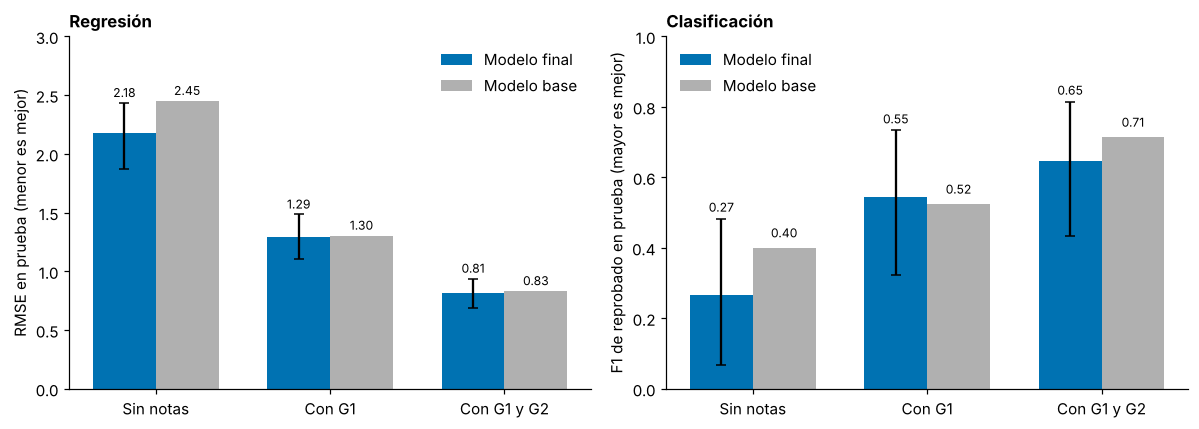

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4)); x = np.arange(3); w = 0.36
fin = [REG[e]["RMSE"] for e in ESC]; bas = [core.BASE_PRUEBA[e]["RMSE"] for e in ESC]
err = np.array([[REG[e]["RMSE"] - REG[e]["ic_rmse"][0], REG[e]["ic_rmse"][1] - REG[e]["RMSE"]] for e in ESC]).T
ax1.bar(x - w / 2, fin, w, yerr=err, capsize=3, color=AZUL, label="Modelo final"); ax1.bar(x + w / 2, bas, w, color=GRIS, label="Modelo base")
for i in range(3): ax1.text(i - w / 2, REG[ESC[i]]["ic_rmse"][1] + 0.05, f"{fin[i]:.2f}", ha="center", fontsize=8); ax1.text(i + w / 2, bas[i] + 0.05, f"{bas[i]:.2f}", ha="center", fontsize=8)
ax1.set_xticks(x); ax1.set_xticklabels(ESC); ax1.set_ylabel("RMSE en prueba (menor es mejor)"); ax1.set_title("Regresión"); ax1.set_ylim(0, 3.0); ax1.legend()
fin = [CLF[e]["F1"] for e in ESC]; bas = [core.BASE_PRUEBA[e]["F1"] for e in ESC]
err = np.array([[CLF[e]["F1"] - CLF[e]["ic_f1"][0], CLF[e]["ic_f1"][1] - CLF[e]["F1"]] for e in ESC]).T
ax2.bar(x - w / 2, fin, w, yerr=err, capsize=3, color=AZUL, label="Modelo final"); ax2.bar(x + w / 2, bas, w, color=GRIS, label="Modelo base")
for i in range(3): ax2.text(i - w / 2, CLF[ESC[i]]["ic_f1"][1] + 0.02, f"{fin[i]:.2f}", ha="center", fontsize=8); ax2.text(i + w / 2, bas[i] + 0.03, f"{bas[i]:.2f}", ha="center", fontsize=8)
ax2.set_xticks(x); ax2.set_xticklabels(ESC); ax2.set_ylabel("F1 de reprobado en prueba (mayor es mejor)"); ax2.set_title("Clasificación"); ax2.set_ylim(0, 1.0); ax2.legend(loc="upper left")
fig.tight_layout(); plt.show()

Figura 4. Comparación del modelo final con el modelo base en el conjunto de prueba. Las barras de error de los modelos finales son los intervalos de confianza del 95 % por bootstrap; los modelos base no tienen intervalo porque sus predicciones no se guardaron. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. La figura resume el balance del trabajo. En regresión el único escenario donde el modelo final se separa con claridad del base es sin notas; con G1 y con G1 y G2 las barras casi coinciden. En clasificación las barras del modelo final no superan a las del base salvo con G1, y las barras de error son anchas, sobre todo sin notas, donde el intervalo del F1 va de 0,07 a 0,48. Más que un fracaso de los modelos, esto muestra el límite de lo que permiten estos datos: una vez que se tienen las notas parciales, un modelo simple es difícil de mejorar, y cuando no se tienen, la información de contexto aporta una señal real pero modesta.

### 3.4 Interpretabilidad

El análisis de la Fase 3 con valores SHAP y con importancia por permutación mostró un patrón estable. Sin notas, las variables que más pesan son el número de reprobaciones previas (permutarla aumenta el RMSE en 0,36 puntos), el deseo de cursar educación superior (0,14), las ausencias, la educación de los padres y el consumo de alcohol; en clasificación se suman la escuela y el indicador de reprobaciones previas. Tener una reprobación previa resta entre 1 y 2,3 puntos a la nota predicha y no querer estudios superiores entre 0,9 y 1,8. Con G1 y G2, en cambio, permutar G2 aumenta el RMSE en más de 2 puntos y G1 en 0,25, mientras que el resto de las variables tiene una importancia prácticamente nula: una vez que se conoce el desempeño reciente, el contexto casi no agrega información. Estas son asociaciones del modelo y no causas; por ejemplo, la escuela puede estar recogiendo diferencias de contexto que el archivo no contiene.

### 3.5 Segmentación

K-Means con cuatro grupos fue la solución elegida con la regla definida de antemano. Se recalcula la silueta con el modelo guardado y se resumen los perfiles con los 649 estudiantes.

In [9]:
s = core.segmentacion()
tr = df[df["particion"] == "entrenamiento"]
Ztr = s["escalador"].transform(tr[s["variables"]])
sil = silhouette_score(Ztr, s["kmeans"].predict(Ztr))
print(f"Silueta de K-Means (K = 4) en entrenamiento: {sil:.3f}")
assert abs(sil - 0.101) < 0.002

perfil = pd.DataFrame({
    "Nombre": [core.GRUPOS[g][0] for g in range(1, 5)],
    "Estudiantes": df.groupby("grupo").size().values,
    "% reprobados": ((1 - df.groupby("grupo")["aprobado"].mean()) * 100).round(1).values,
    "Nota media (sin ceros)": df[df["G3"] > 0].groupby("grupo")["G3"].mean().round(2).values,
    "% con G3 = 0": (df.groupby("grupo")["sin_nota_final"].mean() * 100).round(1).values,
    "Edad": df.groupby("grupo")["age"].mean().round(1).values,
    "Reprobaciones previas": df.groupby("grupo")["failures"].mean().round(2).values,
    "Ausencias": df.groupby("grupo")["absences"].mean().round(1).values,
    "Salidas (1-5)": df.groupby("grupo")["goout"].mean().round(1).values,
    "Alcohol fin de semana (1-5)": df.groupby("grupo")["Walc"].mean().round(1).values,
    "Educ. madre (0-4)": df.groupby("grupo")["Medu"].mean().round(1).values,
}, index=pd.Index(range(1, 5), name="Grupo"))
perfil

Silueta de K-Means (K = 4) en entrenamiento: 0.101


,Nombre,Estudiantes,% reprobados,Nota media (sin ceros),% con G3 = 0,Edad,Reprobaciones previas,Ausencias,Salidas (1-5),Alcohol fin de semana (1-5),Educ. madre (0-4)
Grupo,,,,,,,,,,,
1,Perfil académico sólido,212,5.2,13.54,1.4,16.5,0.01,2.6,3.0,1.8,3.6
2,Hábitos moderados,243,12.3,12.19,1.6,16.6,0.08,2.8,2.8,1.8,1.8
3,Vida social intensa,133,19.5,11.27,1.5,16.8,0.13,6.0,4.2,4.0,2.6
4,Rezago y riesgo alto,61,54.1,9.22,9.8,18.1,1.72,5.7,3.3,2.4,1.8


Tabla 6. Perfil de los cuatro grupos de K-Means con los 649 estudiantes. Los grupos están numerados de menor a mayor tasa de reprobación. Fuente: elaboración propia con datos de Cortez y Silva (2008).

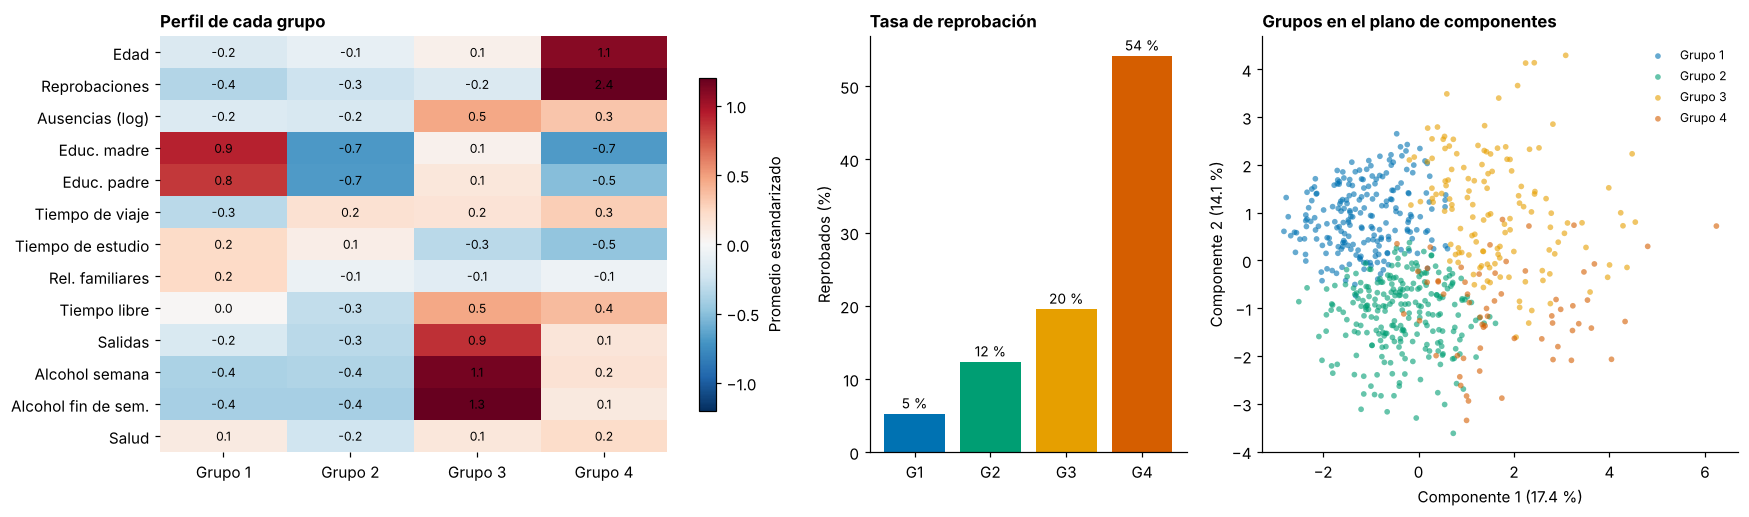

In [10]:
z = core.perfil_estandarizado(); P = core.proyeccion(); ve = core.varianza_explicada()
etq = {"age": "Edad", "failures": "Reprobaciones", "log_ausencias": "Ausencias (log)", "Medu": "Educ. madre", "Fedu": "Educ. padre", "traveltime": "Tiempo de viaje", "studytime": "Tiempo de estudio",
       "famrel": "Rel. familiares", "freetime": "Tiempo libre", "goout": "Salidas", "Dalc": "Alcohol semana", "Walc": "Alcohol fin de sem.", "health": "Salud"}
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 0.8, 1.2]})
im = ax1.imshow(z.values.T, cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax1.set_xticks(range(4)); ax1.set_xticklabels([f"Grupo {g}" for g in z.index]); ax1.set_yticks(range(len(z.columns))); ax1.set_yticklabels([etq[c] for c in z.columns])
for i in range(len(z.columns)):
    for j in range(4): ax1.text(j, i, f"{z.values[j, i]:.1f}", ha="center", va="center", fontsize=8)
for sp in ax1.spines.values(): sp.set_visible(False)
fig.colorbar(im, ax=ax1, shrink=0.8).set_label("Promedio estandarizado"); ax1.set_title("Perfil de cada grupo")
ax2.bar([f"G{g}" for g in perfil.index], perfil["% reprobados"], color=[AZUL, VERDE, AMARILLO, NARANJA])
for i, v in enumerate(perfil["% reprobados"]): ax2.text(i, v + 0.8, f"{v:.0f} %", ha="center", fontsize=9)
ax2.set_ylabel("Reprobados (%)"); ax2.set_title("Tasa de reprobación")
for g, c in zip(range(1, 5), [AZUL, VERDE, AMARILLO, NARANJA]):
    m = (df["grupo"] == g).values; ax3.scatter(P.loc[m, "PC1"], P.loc[m, "PC2"], s=14, alpha=.6, color=c, label=f"Grupo {g}", edgecolor="none")
ax3.set_xlabel(f"Componente 1 ({ve[0] * 100:.1f} %)"); ax3.set_ylabel(f"Componente 2 ({ve[1] * 100:.1f} %)"); ax3.set_title("Grupos en el plano de componentes"); ax3.legend(fontsize=8)
fig.tight_layout(); plt.show()

Figura 5. Perfil estandarizado de cada grupo, tasa de reprobación por grupo y proyección sobre las dos primeras componentes principales. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. La silueta es de 0,101 en entrenamiento, lejos de la meta de 0,25, de modo que los grupos no están bien separados y los estudiantes se mezclan en el plano de componentes (que recoge solo cerca del 32 % de la varianza). A pesar de eso, los grupos son interpretables y separan riesgos muy distintos. El grupo 1 (212 estudiantes, 32,7 %) tiene hogares con mayor nivel educativo (madre de 3,6 en la escala de 0 a 4), consumo de alcohol bajo y una nota media de 13,5; reprueba el 5,2 %. El grupo 2 (243 estudiantes) tiene hábitos parecidos pero hogares de menor nivel educativo y reprueba el 12,3 %. El grupo 3 (133 estudiantes) se distingue por las salidas frecuentes (4,2 en la escala de 1 a 5), el mayor consumo de alcohol de fin de semana (4,0) y más ausencias (6,0); reprueba el 19,5 %. El grupo 4 (61 estudiantes, 9,4 %) reúne a los estudiantes de mayor edad (18,1 años), con 1,7 reprobaciones previas en promedio; reprueba el 54,1 % y tiene la mayor proporción de ceros en la nota final (9,8 %). En términos prácticos, el grupo 4 contiene 33 de los 100 reprobados y los grupos 3 y 4 juntos, con el 30 % de los estudiantes, contienen cerca del 59 %. Las notas no se usaron para formar los grupos, pero la edad y las reprobaciones sí, así que parte de esa separación es esperable.

### 3.6 Dashboard interactivo

El dashboard cumple los cuatro módulos que pide la guía. Los filtros dinámicos permiten segmentar por partición, escuela, sexo, zona, deseo de estudios superiores, grupo y rangos de edad, ausencias, reprobaciones y nota final; como el conjunto no tiene variable de fecha, no hay filtro por fechas y se reemplaza por los rangos numéricos. Las tarjetas de indicadores muestran el número de estudiantes, la tasa de aprobación, los reprobados, la nota media y las ausencias medias de la selección, junto con el R², el error, el F1 y el AUC del modelo en el conjunto de prueba. El módulo de predicción en vivo recibe los datos de un estudiante y devuelve al instante la nota esperada, la probabilidad de reprobar, un nivel de riesgo y el grupo al que se parece. El módulo de segmentación muestra los grupos en el espacio de componentes principales en 2D y 3D, con el estudiante simulado marcado como una estrella, y su perfil promedio. Las demás pestañas comparan los modelos con sus bases y permiten descargar los datos filtrados.

El nivel de riesgo se define con el umbral de cada escenario: es alto cuando la probabilidad supera el umbral ajustado, medio entre la mitad del umbral y el umbral, y bajo por debajo de la mitad. Para ilustrar cómo cambia la predicción al avanzar el año, la Tabla 7 muestra tres estudiantes hipotéticos evaluados con el mismo paquete que usa el dashboard.

In [11]:
ejemplos = {
    "A. Perfil típico (GP, quiere estudiar, sin reprobaciones)": {"G1": 14, "G2": 15},
    "B. MS, no quiere estudiar, una reprobación, 18 años": {"school": "MS", "higher": "no", "failures": 1, "absences": 6, "age": 18, "studytime": 1, "G1": 9, "G2": 8},
    "C. Mismo contexto que A con notas bajas": {"G1": 6, "G2": 4},
}
filas = []
for nombre, e in ejemplos.items():
    fila = {"Estudiante": nombre}
    for esc in ESC:
        r = core.predecir(esc, e)
        fila[esc] = f"nota {r['nota']:.1f}; riesgo {r['riesgo'].lower()} ({r['p_reprobar'] * 100:.0f} %)"
    fila["Grupo"] = core.asignar_grupo(e)
    filas.append(fila)
tabla_ej = pd.DataFrame(filas).set_index("Estudiante")
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 220)
tabla_ej

,Sin notas,Con G1,Con G1 y G2,Grupo
Estudiante,,,,
"A. Perfil típico (GP, quiere estudiar, sin reprobaciones)",nota 13.0; riesgo bajo (5 %),nota 14.3; riesgo bajo (1 %),nota 15.1; riesgo bajo (1 %),2
"B. MS, no quiere estudiar, una reprobación, 18 años",nota 8.5; riesgo alto (94 %),nota 9.7; riesgo alto (90 %),nota 8.8; riesgo alto (95 %),4
C. Mismo contexto que A con notas bajas,nota 13.0; riesgo bajo (5 %),nota 7.8; riesgo alto (95 %),nota 5.4; riesgo alto (93 %),2


Tabla 8. Predicciones del paquete para tres estudiantes hipotéticos en los tres escenarios. Los valores de la nota en los escenarios sin notas ignoran G1 y G2. Fuente: elaboración propia con los modelos de la Fase 3.

Análisis. El estudiante A tiene riesgo bajo en los tres escenarios (5 %, 1 % y 1 %) y la nota esperada sube de 13,0 a 15,1 a medida que se agregan sus notas. El estudiante B, con un contexto de mayor riesgo (escuela MS, sin deseo de cursar estudios superiores, una reprobación previa y 18 años), tiene riesgo alto desde el inicio (94 % sin notas) y los modelos con notas lo confirman (90 % y 95 %); el modelo lo ubica además en el grupo 4. El estudiante C es el caso más ilustrativo: con el mismo contexto de A, el escenario sin notas lo ve en riesgo bajo (5 %), pero al conocerse su G1 de 6 el riesgo pasa a 95 % y la nota esperada baja de 13,0 a 7,8, y a 5,4 con G2. Es decir, el contexto por sí solo no detecta a un estudiante cuyo desempeño se deteriora, y por eso el dashboard permite cambiar de escenario a medida que llega información. Son casos inventados para ilustrar el comportamiento del paquete, no estudiantes reales.

Sobre la eficiencia, se midió cuánto tarda el paquete en cargar los modelos y en responder una predicción. Esas dos cantidades determinan qué tan fluido se siente el dashboard, porque cada vez que el usuario mueve un control Streamlit vuelve a ejecutar el script.

In [12]:
core.modelo.cache_clear(); core.segmentacion.cache_clear(); core._pca.cache_clear()
t0 = time.perf_counter()
for esc in ESC:
    core.modelo("reg", esc); core.modelo("clf", esc)
core.segmentacion(); core.proyeccion()
carga = time.perf_counter() - t0
e = {"school": "MS", "higher": "no", "failures": 1, "G1": 9, "G2": 8}
core.predecir("Con G1 y G2", e)  # calentamiento
tiempos = []
for _ in range(200):
    t0 = time.perf_counter(); core.predecir("Con G1 y G2", e); core.asignar_grupo(e); core.proyectar(e); tiempos.append((time.perf_counter() - t0) * 1000)
mb = sum(p.stat().st_size for p in core.MODELOS.glob("*.joblib")) / 1e6
print(f"Carga única de los 6 modelos, la segmentación y la proyección: {carga:.2f} s")
print(f"Respuesta de una interacción completa (nota, riesgo, grupo y posición en el mapa): mediana {np.median(tiempos):.1f} ms, percentil 95 {np.percentile(tiempos, 95):.1f} ms")
print(f"Tamaño total de los modelos guardados: {mb:.2f} MB")
assert np.median(tiempos) < 200 and np.percentile(tiempos, 95) < 300

Carga única de los 6 modelos, la segmentación y la proyección: 0.02 s
Respuesta de una interacción completa (nota, riesgo, grupo y posición en el mapa): mediana 15.2 ms, percentil 95 20.3 ms
Tamaño total de los modelos guardados: 1.05 MB


Análisis. En la ejecución de este cuaderno, cargar los seis modelos, la segmentación y la proyección toma una fracción de segundo y los archivos pesan en total poco más de 1 MB. Una interacción completa, que incluye la nota esperada, el nivel de riesgo, el grupo y la posición del estudiante en el mapa, tarda en el orden de 20 ms (mediana), con el percentil 95 por debajo de 30 ms; las cifras exactas cambian de una ejecución a otra y dependen del equipo. Lo importante es que la parte de predicción no es el cuello de botella: al estar los modelos ya entrenados y guardados, el dashboard no reentrena nada y cada control solo dispara una predicción sobre una fila. Lo que sí tardará más en un navegador es el dibujo de los gráficos de Plotly, que no se midió aquí. Otras decisiones de eficiencia son que los modelos se cargan una sola vez por proceso y se reutilizan en cada interacción, que las versiones exactas de las dependencias evitan errores al cargar los archivos y que el script de arranque usa uv cuando está disponible para instalar mucho más rápido.

## 4. Discusión

### 4.1 Qué tanto se puede predecir y cuándo

Los resultados cuentan una historia coherente con lo que mostraron las fases anteriores. La nota final es muy predecible cuando se conocen las notas parciales (R² de 0,90 con G1 y G2) y bastante menos cuando solo se conoce el contexto (R² de 0,31). Eso es consistente con lo que reportan Cortez y Silva (2008): las evaluaciones previas son el mejor predictor del resultado final, y sin ellas la tarea es más difícil. Lo que aporta este trabajo es cuantificar esa diferencia por escenario y mostrar que el contexto y los hábitos no son irrelevantes: antes de cualquier calificación reducen el error de la regresión en 11 % frente a usar solo las reprobaciones previas y explican cerca de un tercio de la variación de la nota. Ese es el escenario que serviría para intervenir temprano, pero también el de mayor incertidumbre: el error típico de unos 2,2 puntos sobre 20 sirve para priorizar acompañamiento, no para anticipar la nota de un estudiante concreto.

### 4.2 Por qué los modelos complejos no ganaron en clasificación

En clasificación los modelos ajustados no superaron de forma consistente a los modelos base, y hay varias razones que se apoyan en los resultados. Con G1 o G2 la tarea se parece a ver si una nota parcial queda por debajo de un umbral, y un modelo simple ya la captura. Los modelos flexibles sobreajustaron (la precisión promedio de Random Forest fue de 1,00 en entrenamiento contra valores de 0,5 a 0,9 en validación), y con 551 estudiantes de entrenamiento y solo 85 reprobados no hay datos suficientes para que esa flexibilidad compense. Además, elegir el mejor entre varios candidatos con una validación de 15 reprobados tiende a sobrestimar su desempeño: el AUC del mejor modelo sin notas bajó de 0,81 en validación a 0,66 en prueba. Por último, los intervalos de confianza se traslapan por completo con los del modelo base, de modo que las diferencias no son concluyentes en ninguna dirección. La lectura prudente es que la ventaja de los modelos complejos no se pudo demostrar con estos datos.

### 4.3 Los perfiles y su uso

La segmentación tiene un resultado mixto. La silueta (0,10) incumple la meta de 0,25 de la Fase 1 y DBSCAN no encontró estructura de densidad en ninguna configuración, lo que indica que los estudiantes forman un continuo y no grupos naturales. Aun así, los cuatro grupos de K-Means separan riesgos muy distintos sin haber usado las notas, y sus perfiles son interpretables. Hay que ser cuidadoso en una cosa: la edad y las reprobaciones previas entran a la segmentación y están muy relacionadas con el resultado, por lo que parte de la diferencia del grupo 4 es esperable por construcción. Los grupos sirven como una forma de orientar el tipo de apoyo (académico, de hábitos, familiar), no como categorías que describan a las personas.

### 4.4 Limitaciones y consideraciones éticas

Las limitaciones principales son las siguientes. Los datos son de dos escuelas de Portugal y de una sola asignatura, por lo que no se pueden generalizar sin cuidado. La validación y la prueba tienen solo 15 reprobados cada una y todas las métricas de clasificación son ruidosas. Los quince ceros se interpretaron como abandonos con base en patrones de los datos y no en documentación del archivo. Varias variables son autorreportadas, como el consumo de alcohol. Y las asociaciones no son causales.

Hay además una consideración ética. Algunas variables que pesan en los modelos, como la escuela, el sexo o la educación de los padres, son características que un estudiante no controla, y usar una predicción para etiquetar o limitar oportunidades sería inapropiado. Por eso el dashboard presenta la probabilidad como un nivel de riesgo, advierte su incertidumbre y declara que es una herramienta académica. Un uso responsable sería para orientar recursos de apoyo con revisión humana, y antes de cualquier uso real habría que evaluar si el modelo funciona igual de bien en distintos grupos de estudiantes, algo que este trabajo no hizo.

## 5. Conclusiones

La pregunta principal se puede responder así: las características académicas, familiares y de hábitos permiten predecir la nota final con un error que depende de lo que se conozca. Con las notas de los dos primeros periodos el error típico es menor a un punto (RMSE de 0,81 y R² de 0,90); con solo la del primer periodo es de 1,29 (R² de 0,76); y sin ninguna nota es de 2,18 (R² de 0,31). La aprobación se puede ordenar por riesgo con un AUC de 0,95, 0,88 y 0,66 en los tres escenarios, pero con intervalos amplios y sin demostrar ventaja sobre los modelos simples.

Respecto a las preguntas secundarias. Las variables más asociadas con el desempeño, además de las notas parciales, son las reprobaciones previas, el deseo de cursar educación superior, la escuela, el nivel educativo de los padres, las ausencias y el consumo de alcohol. Las notas parciales aportan casi todo el poder predictivo: cuando se conocen, el contexto prácticamente no agrega información, y su valor está en el escenario temprano. Y sí existen perfiles diferenciados, cuatro en total, con tasas de reprobación de 5 % a 54 %, aunque no son grupos nítidos.

La tabla siguiente contrasta los resultados con las metas SMART planteadas en la Fase 1.

In [13]:
filas = []
for esc in ESC:
    filas.append({"Meta": f"Regresión ({esc}): RMSE menor que el base", "Resultado en prueba": f"{REG[esc]['RMSE']:.2f} frente a {core.BASE_PRUEBA[esc]['RMSE']:.2f}",
                  "Cumplida": "Sí" if REG[esc]["RMSE"] < core.BASE_PRUEBA[esc]["RMSE"] else "No"})
for esc in ESC:
    filas.append({"Meta": f"Clasificación ({esc}): F1 de reprobado mayor que el base", "Resultado en prueba": f"{CLF[esc]['F1']:.2f} frente a {core.BASE_PRUEBA[esc]['F1']:.2f}",
                  "Cumplida": "Sí" if CLF[esc]["F1"] > core.BASE_PRUEBA[esc]["F1"] else "No"})
filas.append({"Meta": "Al menos dos modelos de regresión, dos de clasificación y un perceptrón multicapa", "Resultado en prueba": "5 de regresión, 4 de clasificación y MLP en PyTorch", "Cumplida": "Sí"})
filas.append({"Meta": "Silueta promedio de al menos 0,25 en la segmentación", "Resultado en prueba": f"{sil:.2f} (K-Means, K = 4)", "Cumplida": "Sí" if sil >= 0.25 else "No"})
filas.append({"Meta": "Dashboard con filtros, indicadores, predicción en vivo y mapa de grupos", "Resultado en prueba": "Los cuatro módulos funcionan (pruebas automáticas y servidor local)", "Cumplida": "Sí"})
filas.append({"Meta": "Dashboard desplegado en vivo con URL pública", "Resultado en prueba": "Pendiente de publicar (anexo A)", "Cumplida": "Pendiente"})
pd.DataFrame(filas).set_index("Meta")

,Resultado en prueba,Cumplida
Meta,,
Regresión (Sin notas): RMSE menor que el base,2.18 frente a 2.45,Sí
Regresión (Con G1): RMSE menor que el base,1.29 frente a 1.30,Sí
Regresión (Con G1 y G2): RMSE menor que el base,0.81 frente a 0.83,Sí
Clasificación (Sin notas): F1 de reprobado mayor que el base,0.27 frente a 0.40,No
Clasificación (Con G1): F1 de reprobado mayor que el base,0.55 frente a 0.52,Sí
Clasificación (Con G1 y G2): F1 de reprobado mayor que el base,0.65 frente a 0.71,No
"Al menos dos modelos de regresión, dos de clasificación y un perceptrón multicapa","5 de regresión, 4 de clasificación y MLP en PyTorch",Sí
"Silueta promedio de al menos 0,25 en la segmentación","0.10 (K-Means, K = 4)",No
"Dashboard con filtros, indicadores, predicción en vivo y mapa de grupos",Los cuatro módulos funcionan (pruebas automáticas y servidor local),Sí


Tabla 9. Cumplimiento de las metas del proyecto. Fuente: elaboración propia.

Las metas de RMSE se cumplieron en los tres escenarios, aunque con mejoras pequeñas cuando hay notas; la de F1 se cumplió en un escenario de tres; la de silueta no se cumplió; y el dashboard funciona localmente y en pruebas, pero la publicación con URL pública depende de subir el repositorio a una plataforma, paso que se describe en el anexo A. Estos resultados se reportan sin ajustes posteriores a la evaluación en prueba, para no contaminarla.

## 6. Trabajo futuro

Hay varias líneas naturales para continuar. La más importante es validar externamente los modelos: el mismo estudio publicó el archivo de matemáticas con estudiantes de las mismas escuelas, que permitiría comprobar si los patrones se sostienen en otra asignatura, y con más estudiantes se podría tener una prueba con más reprobados y métricas más estables. Segundo, calibrar las probabilidades (por ejemplo con regresión isotónica) para que un riesgo del 40 % corresponda a una frecuencia observada del 40 %, y elegir el umbral según el costo de no detectar a un estudiante en riesgo frente al de intervenir de más. Tercero, evaluar la equidad de los modelos entre escuelas y sexos antes de cualquier uso real. Cuarto, tratar el abandono como un problema aparte, con un modelo de supervivencia o de clasificación propio, ya que los quince ceros quedaron fuera de la regresión. Quinto, mejorar la segmentación con métodos pensados para variables mixtas, como K-Prototypes o la distancia de Gower, y verificar la estabilidad de los grupos. Por último, en el dashboard se podría incorporar la explicación individual con SHAP para que cada predicción muestre qué variables la empujan, y un esquema de monitoreo para detectar si los datos nuevos se alejan de los de entrenamiento.

## 7. Referencias

Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5-32.

Chawla, N. V., Bowyer, K. W., Hall, L. O., y Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. Journal of Artificial Intelligence Research, 16, 321-357.

Chen, T., y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785-794.

Cortez, P. (2008). Student Performance [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

Cortez, P., y Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito y J. Teixeira (Eds.), Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008) (pp. 5-12). EUROSIS.

Efron, B., y Tibshirani, R. J. (1993). An introduction to the bootstrap. Chapman & Hall.

Ester, M., Kriegel, H.-P., Sander, J., y Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. Proceedings of the 2nd International Conference on Knowledge Discovery and Data Mining, 226-231.

Hoerl, A. E., y Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. Technometrics, 12(1), 55-67.

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Lloyd, S. P. (1982). Least squares quantization in PCM. IEEE Transactions on Information Theory, 28(2), 129-137.

Lundberg, S. M., y Lee, S.-I. (2017). A unified approach to interpreting model predictions. Advances in Neural Information Processing Systems, 30, 4765-4774.

Okabe, M., e Ito, K. (2008). Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people. https://jfly.uni-koeln.de/color/

Paszke, A., Gross, S., Massa, F., et al. (2019). PyTorch: An imperative style, high-performance deep learning library. Advances in Neural Information Processing Systems, 32, 8024-8035.

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825-2830.

Plotly Technologies Inc. (2015). Collaborative data science. Plotly Technologies Inc. https://plot.ly

Romero, C., y Ventura, S. (2010). Educational data mining: A review of the state of the art. IEEE Transactions on Systems, Man, and Cybernetics, Part C, 40(6), 601-618.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53-65.

Streamlit Inc. (s. f.). Streamlit [Software]. https://streamlit.io

Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. Journal of the Royal Statistical Society: Series B, 58(1), 267-288.

Zou, H., y Hastie, T. (2005). Regularization and variable selection via the elastic net. Journal of the Royal Statistical Society: Series B, 67(2), 301-320.

## 8. Anexo A. Reproducibilidad, despliegue y lista de chequeo

### A.1 Estructura del repositorio y ejecución

El repositorio sigue la estructura pedida por la guía. La carpeta data tiene el archivo original y los datos preparados, modelos tiene los modelos finales y la segmentación, src contiene el paquete rendimiento con la lógica compartida, dashboard tiene la aplicación, notebooks tiene los cuadernos de las cuatro fases y tests tiene las pruebas automáticas. El archivo requirements.txt fija las versiones exactas de las dependencias del dashboard (streamlit 1.67.0, plotly 7.2.0, pandas 3.0.5, numpy 2.5.3, scipy 1.18.1, scikit-learn 1.9.1, xgboost 3.4.1 y joblib 1.6.0) y requirements-notebooks.txt agrega lo necesario para reproducir los cuadernos (PyTorch, SHAP e imbalanced-learn). Las versiones de scikit-learn y XGBoost importan porque los archivos joblib de los modelos no son portables entre versiones distintas.

Para ejecutar el dashboard basta con el script run.sh en Linux y macOS o run.bat en Windows, que crean un entorno virtual, instalan las dependencias (con uv si está disponible) y lanzan la aplicación en http://localhost:8501. Para correr las pruebas, que verifican que los modelos reproducen las métricas de prueba de la Fase 3 y que el dashboard responde a sus controles, se usa pytest.

### A.2 Despliegue en vivo

La guía pide un dashboard desplegado. La forma más sencilla es Streamlit Community Cloud: se sube el repositorio a GitHub, se elige el archivo dashboard/app.py en https://share.streamlit.io y la plataforma instala requirements.txt y entrega una URL pública. Ese paso lo hace el autor con su propia cuenta; la URL se agrega a este informe una vez publicada.

### A.3 Lista de chequeo de la Fase 4

| Requisito de la guía | Estado |
|---|---|
| Filtros dinámicos | Hecho, con la salvedad de que el conjunto no tiene fechas y se filtra por rangos numéricos y categorías |
| Tarjetas KPI | Hecho |
| Módulo de predicción en vivo | Hecho |
| Módulo de segmentación con gráfico interactivo 2D o 3D | Hecho |
| Informe con estructura de artículo | Este cuaderno |
| Repositorio con /data, /notebooks, /src, /dashboard y requirements.txt | Hecho; falta publicarlo en GitHub o GitLab |
| Dashboard desplegado en vivo | Pendiente de publicar |
| Exposición de 12 minutos con demostración en vivo | Pendiente (28 de noviembre) |

{T()}. Lista de chequeo del Entregable 4. Fuente: elaboración propia a partir de la guía del proyecto.